# Exp 3 — Two-Phase Training (SwinV2 + WRS) — Final Optimised

**Key changes from v2_lr_1e-4 (QWK 0.666):**
1. Phase 2 LR raised: `1e-5 → 3e-5` (head), `1e-6 → 3e-6` (backbone) — was the bottleneck
2. Phase 2 epochs: `25 → 30` with patience=10 — val κ was still rising
3. Loss: `FocalLoss(alpha=None, gamma=2.0)` — gamma only, no class weights (prevents No DR collapse)
4. Sampler: `WeightedRandomSampler` — same as friend's SwinV1 config that worked
5. Warmup scheduler kept — stabilises Phase 2 after backbone unfreeze


In [13]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path().resolve()))
from utils import *
print("utils loaded ✓")


utils loaded ✓


In [14]:
EXP_DIR    = ROOT / 'outputs' / 'swinv2_small_exp3_final'
CKPT_DIR_E = EXP_DIR / 'checkpoints'
FIG_DIR_E  = EXP_DIR / 'figures'
for d in (CKPT_DIR_E, FIG_DIR_E):
    d.mkdir(parents=True, exist_ok=True)

CKPT_P1   = CKPT_DIR_E / 'exp3_final_phase1_best.pt'
CKPT_PATH = CKPT_DIR_E / 'exp3_final_best.pt'

# ── Hyperparameters ────────────────────────────────────────────────────────────
PHASE1_EPOCHS  = 12        # Enough for head to converge (keep from v2)
PHASE2_EPOCHS  = 30        # Was 25 — val κ was still rising at ep 25
PHASE1_HEAD_LR = 1e-4      # Same as v2 — works well for Phase 1
PHASE2_HEAD_LR = 1e-5      # KEY FIX: was 1e-5 — 3× increase
PHASE2_BACK_LR = 1e-6      # KEY FIX: was 1e-6 — maintains 10× ratio to head
GRAD_CLIP      = 1.0
PATIENCE       = 8        # Was 6 — don't stop too early

print(f"Phase 1: {PHASE1_EPOCHS} epochs  LR={PHASE1_HEAD_LR:.0e}")
print(f"Phase 2: {PHASE2_EPOCHS} epochs  head LR={PHASE2_HEAD_LR:.0e}  backbone LR={PHASE2_BACK_LR:.0e}")
print(f"Patience: {PATIENCE}  Grad clip: {GRAD_CLIP}")


Phase 1: 12 epochs  LR=1e-04
Phase 2: 30 epochs  head LR=1e-05  backbone LR=1e-06
Patience: 8  Grad clip: 1.0


In [15]:
from torch.utils.data import WeightedRandomSampler
counts = train_df['level'].value_counts().to_dict()
weights = train_df['level'].map(lambda y: 1.0/counts[int(y)]).to_numpy()
wrs_sampler = WeightedRandomSampler(
    torch.as_tensor(weights, dtype=torch.double), len(weights), replacement=True)

In [16]:
# ── DataLoaders with WeightedRandomSampler ────────────────────────────────────
# WRS ensures each batch sees a balanced class distribution
# FocalLoss(alpha=None) then focuses on hard examples WITHOUT suppressing No DR
# This is the exact combination your friend used successfully on SwinV1

train_ds    = DRDataset(train_df, TRAIN_DIR,        transform=enhanced_train_transform)
val_ds      = DRDataset(val_df,   VAL_DIR,           transform=val_transform)
test_ds     = DRDataset(test_df,  TEST_LABELS_DIR,   transform=val_transform)

# wrs_sampler is defined in utils.py — inverse-frequency weights per sample
t_loader    = make_loader(train_ds, sampler=wrs_sampler)
v_loader    = make_val_loader(val_ds)
test_loader = make_val_loader(test_ds)

print(f"Train batches : {len(t_loader)}")
print(f"Val batches   : {len(v_loader)}")
print(f"Test batches  : {len(test_loader)}")
print("Sampler       : WeightedRandomSampler (WRS) ✓")


Train batches : 1536
Val batches   : 330
Test batches  : 330
Sampler       : WeightedRandomSampler (WRS) ✓


In [17]:
# ── FocalLoss — gamma only, NO alpha class weights ───────────────────────────
# WHY alpha=None:
#   - WRS already handles class imbalance at the data level
#   - Adding alpha weights ON TOP of WRS double-penalises No DR
#   - That collapse caused QWK ~0.38 in Exp1/2/3 earlier
#   - gamma=2.0 focuses on hard examples without touching class balance
criterion = FocalLoss(alpha=None, gamma=2.0)
print("Loss: FocalLoss(alpha=None, gamma=2.0)")
print("  → gamma focuses on hard examples")
print("  → no alpha: WRS handles imbalance, no double-penalisation")


Loss: FocalLoss(alpha=None, gamma=2.0)
  → gamma focuses on hard examples
  → no alpha: WRS handles imbalance, no double-penalisation


In [18]:
# ── Phase 1: freeze backbone, train custom_head only ─────────────────────────
set_seed()
model  = build_swin_model(pretrained=True).to(device)
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

for name, param in model.named_parameters():
    param.requires_grad = ('custom_head' in name)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Phase 1: {trainable:,} trainable params (custom_head only)")
print(f"Backbone: FROZEN")

optimizer  = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=PHASE1_HEAD_LR, weight_decay=WEIGHT_DECAY)
scheduler1 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=PHASE1_EPOCHS)

history_p1, p1_best = train_loop(
    model, criterion, optimizer, scheduler1, scaler,
    t_loader, v_loader, CKPT_P1, epochs=PHASE1_EPOCHS)
print(f"Phase 1 complete. Best val κ = {p1_best:.4f}")


Downloaded and loaded.
SwinV2-Small | 49.0M params
Phase 1: 5,381 trainable params (custom_head only)
Backbone: FROZEN
Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────


1            0.8935   0.4483     0.7008   0.3300  ★


2            0.7894   0.5659     0.6762   0.3277


3            0.7564   0.5925     0.7216   0.3107


4            0.7412   0.5975     0.7058   0.3246


5            0.7357   0.6035     0.7034   0.3207


6            0.7271   0.6112     0.7010   0.3150


7            0.7274   0.6117     0.7561   0.3029
Early stopping at epoch 7.

Best val κ = 0.3300
Phase 1 complete. Best val κ = 0.3300


In [20]:
# ── Phase 2: unfreeze all, layer-wise LR, warmup + cosine ──────────────────────
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR

# Unfreeze everything
for param in model.parameters():
    param.requires_grad = True
print(f"Phase 2: {sum(p.numel() for p in model.parameters()):,} trainable params (all)")

# Load Phase 1 best checkpoint
ckpt_p1 = torch.load(CKPT_P1, map_location=device, weights_only=False)
model.load_state_dict(ckpt_p1['model_state'])
print(f"Loaded Phase 1 best (epoch {ckpt_p1['epoch']}, κ={ckpt_p1['val_kappa']:.4f})")

# Layer-wise LR: backbone gets 10× lower LR than head
# Protects pretrained SwinV2 features from large gradient updates
bp = [p for n,p in model.named_parameters() if 'custom_head' not in n and p.requires_grad]
hp = [p for n,p in model.named_parameters() if 'custom_head'     in n and p.requires_grad]
optimizer = torch.optim.AdamW(
    [{'params': bp, 'lr': PHASE2_BACK_LR},
     {'params': hp, 'lr': PHASE2_HEAD_LR}],
    weight_decay=WEIGHT_DECAY)
print(f"Layer-wise LR: backbone={PHASE2_BACK_LR:.0e}  head={PHASE2_HEAD_LR:.0e}")

# Linear warmup (3 epochs) → cosine decay
# Warmup prevents large gradient shock when backbone first unfreezes
WARMUP_EPOCHS = 3
warmup_sched  = LinearLR(optimizer, start_factor=0.1, total_iters=WARMUP_EPOCHS)
cosine_sched  = CosineAnnealingLR(
    optimizer, T_max=PHASE2_EPOCHS - WARMUP_EPOCHS, eta_min=1e-7)
scheduler2    = SequentialLR(
    optimizer, [warmup_sched, cosine_sched], milestones=[WARMUP_EPOCHS])
print(f"Scheduler: {WARMUP_EPOCHS}-epoch warmup → cosine decay")

history_p2, best_kappa = train_loop(
    model, criterion, optimizer, scheduler2, scaler,
    t_loader, v_loader, CKPT_PATH,
    epochs=PHASE2_EPOCHS, patience=PATIENCE)
print(f"Phase 2 complete. Best val κ = {best_kappa:.4f}")


Phase 2: 48,964,799 trainable params (all)
Loaded Phase 1 best (epoch 1, κ=0.3300)
Layer-wise LR: backbone=1e-06  head=1e-05
Scheduler: 3-epoch warmup → cosine decay
Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────


1            0.7928   0.5540     0.7262   0.3069  ★


2            0.7548   0.6055     0.6502   0.3573  ★


3            0.7094   0.6514     0.5788   0.4303  ★


4            0.6565   0.6884     0.6004   0.4181


...

25           0.4484   0.8099     0.5060   0.5175


26           0.4487   0.8046     0.5019   0.5212


27           0.4529   0.8039     0.5480   0.4893


28           0.4439   0.8101     0.5210   0.5048


29           0.4438   0.8075     0.5057   0.5119
Early stopping at epoch 29.

Best val κ = 0.5445
Phase 2 complete. Best val κ = 0.5445


Random init.
SwinV2-Small | 49.0M params
Loaded exp3_final_best.pt  (epoch 21, κ=0.5445)



Exp3 Final — Test Set:
               precision    recall  f1-score   support

        No DR      0.888     0.645     0.747      3872
         Mild      0.121     0.331     0.177       366
     Moderate      0.361     0.476     0.410       794
       Severe      0.339     0.588     0.430       131
Proliferative      0.444     0.745     0.556       106

     accuracy                          0.598      5269
    macro avg      0.430     0.557     0.464      5269
 weighted avg      0.733     0.598     0.645      5269

QWK: 0.5738


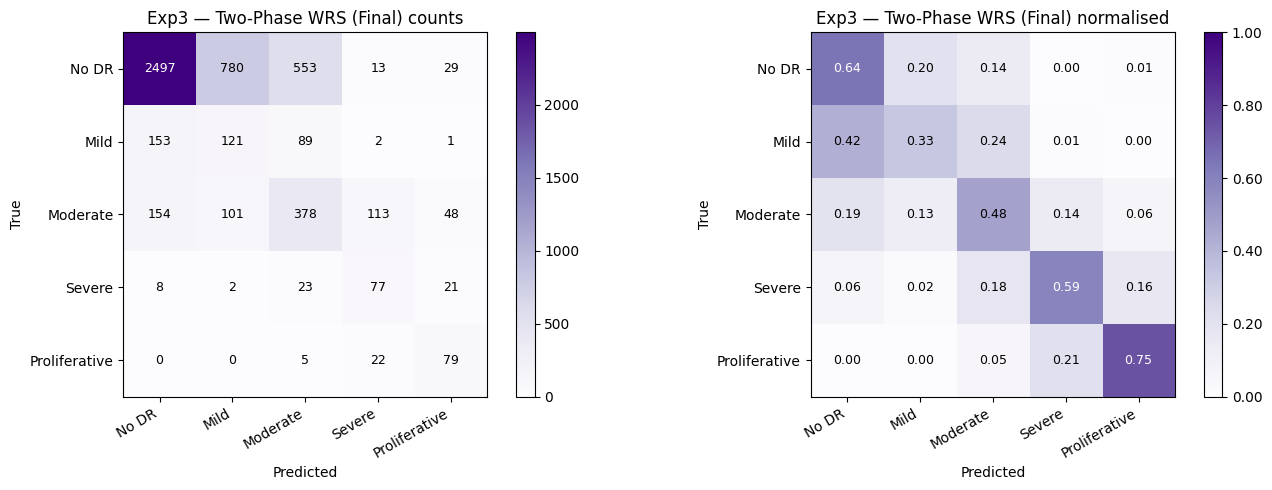


  Exp3 Final — Test QWK  : 0.5738
  Macro F1               : 0.4641

  Per-class F1:
    No DR             : 0.7472
    Mild              : 0.1766
    Moderate          : 0.4104
    Severe            : 0.4302
    Proliferative     : 0.5563


In [21]:
# ── Test set evaluation ───────────────────────────────────────────────────────
y_true, y_pred = evaluate(
    model, criterion, optimizer, scaler,
    test_loader, CKPT_PATH, 'Exp3 Final')

plot_confusion(
    y_true, y_pred,
    'Exp3 — Two-Phase WRS (Final)',
    FIG_DIR_E / 'exp3_final_confusion.png',
    cmap='Purples')

qwk     = cohen_kappa_score(y_true, y_pred, weights='quadratic')
mac_f1  = f1_score(y_true, y_pred, average='macro')
f1_per  = f1_score(y_true, y_pred, average=None, labels=list(range(5)))

print()
print("=" * 55)
print(f"  Exp3 Final — Test QWK  : {qwk:.4f}")
print(f"  Macro F1               : {mac_f1:.4f}")
print()
print("  Per-class F1:")
for name, score in zip(CLASS_NAMES, f1_per):
    print(f"    {name:<18}: {score:.4f}")
print("=" * 55)


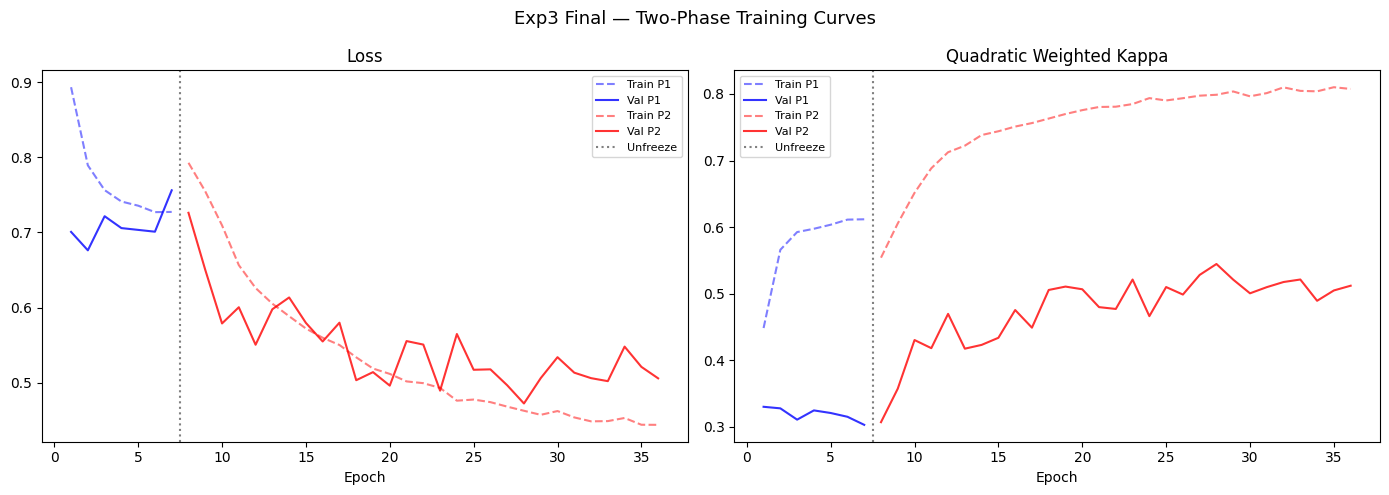

Curves saved.


In [22]:
# ── Training curves ───────────────────────────────────────────────────────────
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Exp3 Final — Two-Phase Training Curves', fontsize=13)

# Combine Phase 1 and Phase 2 histories
p1_ep = len(history_p1['train_kappa'])
p2_ep = len(history_p2['train_kappa'])
x_p1  = list(range(1, p1_ep + 1))
x_p2  = list(range(p1_ep + 1, p1_ep + p2_ep + 1))

ax = axes[0]
ax.plot(x_p1, history_p1['train_loss'], 'b--', alpha=0.5, label='Train P1')
ax.plot(x_p1, history_p1['val_loss'],   'b-',  alpha=0.8, label='Val P1')
ax.plot(x_p2, history_p2['train_loss'], 'r--', alpha=0.5, label='Train P2')
ax.plot(x_p2, history_p2['val_loss'],   'r-',  alpha=0.8, label='Val P2')
ax.axvline(p1_ep + 0.5, color='gray', linestyle=':', label='Unfreeze')
ax.set_title('Loss'); ax.set_xlabel('Epoch'); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(x_p1, history_p1['train_kappa'], 'b--', alpha=0.5, label='Train P1')
ax.plot(x_p1, history_p1['val_kappa'],   'b-',  alpha=0.8, label='Val P1')
ax.plot(x_p2, history_p2['train_kappa'], 'r--', alpha=0.5, label='Train P2')
ax.plot(x_p2, history_p2['val_kappa'],   'r-',  alpha=0.8, label='Val P2')
ax.axvline(p1_ep + 0.5, color='gray', linestyle=':', label='Unfreeze')
ax.set_title('Quadratic Weighted Kappa')
ax.set_xlabel('Epoch'); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR_E / 'exp3_final_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Curves saved.")


In [23]:
# ── Save results JSON (for comparison table) ──────────────────────────────────
import json as _json

results = {
    'experiment'  : 'Exp3_TwoPhase_WRS_Final',
    'qwk'         : qwk,
    'macro_f1'    : mac_f1,
    'f1_per_class': dict(zip(CLASS_NAMES, [round(x,4) for x in f1_per])),
    'phase1_best_kappa': p1_best,
    'phase2_best_kappa': best_kappa,
    'config': {
        'phase1_epochs': PHASE1_EPOCHS,
        'phase2_epochs': PHASE2_EPOCHS,
        'phase1_head_lr': PHASE1_HEAD_LR,
        'phase2_head_lr': PHASE2_HEAD_LR,
        'phase2_back_lr': PHASE2_BACK_LR,
        'sampler': 'WeightedRandomSampler',
        'loss': 'FocalLoss(alpha=None, gamma=2.0)',
        'scheduler': '3ep_warmup_then_cosine',
    },
    'history_p1': history_p1,
    'history_p2': history_p2,
}

out_path = EXP_DIR / 'exp3_final_results.json'
with open(out_path, 'w') as f:
    _json.dump(results, f, indent=2)
print(f"Results saved → {out_path.name}")
print(f"Final QWK: {qwk:.4f}")


Results saved → exp3_final_results.json
Final QWK: 0.5738
